# Accidentes SAMUR Madrid, 2024

Este cuaderno lee el CSV original y el dataset limpio del caso 2.1, **dibuja el proceso de limpieza** y saca unas cuantas lecturas útiles para gravedad, volumen y cobertura del RAG.

| Fuente | Ruta | Filas |
| --- | --- | --- |
| Bruto | `data/accidentes.csv` | 2 062 (con 100 incidencias duplicadas) |
| Limpio | `data_clean/accidentes_clean-2.csv` | 1 962 (una fila por `numero_incidencia`) |

Las figuras se guardan en `data_viz/graficos_accidentes/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

HERE = Path.cwd()
ROOT = next(
    candidate
    for candidate in (HERE, HERE.parent, HERE / "data_viz")
    if (candidate / "data" / "accidentes.csv").exists()
)
VIZ = ROOT / "data_viz" / "graficos_accidentes"
VIZ.mkdir(exist_ok=True)

RAW_PATH = ROOT / "data" / "accidentes.csv"
CLEAN_PATH = ROOT / "data_clean" / "accidentes_clean-2.csv"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "savefig.dpi": 140,
    "savefig.bbox": "tight",
})
PALETTE = ["#1f4e79", "#c0392b", "#e67e22", "#1abc9c", "#7f8c8d", "#8e44ad"]


def savefig(name: str):
    path = VIZ / name
    plt.savefig(path)
    print(path.relative_to(ROOT))


raw = pd.read_csv(RAW_PATH)
clean = pd.read_csv(CLEAN_PATH)
clean["fecha"] = pd.to_datetime(clean["fecha"])
clean["con_moto"] = clean["motos_implicadas"].fillna(0).ge(1)
clean["con_pesado"] = clean["pesados_implicados"].fillna(0).ge(1)
clean["hora_int"] = clean["hora_decimal"].fillna(0).astype(int).clip(0, 23)

print(f"raíz: {ROOT}")
print(f"bruto  {raw.shape}  ← {RAW_PATH.name}")
print(f"limpio {clean.shape}  ← {CLEAN_PATH.name}")
print(clean[["fecha", "hora", "numero_incidencia", "tipo_colision", "grave"]].head(3).to_string(index=False))

raíz: /Users/koss/Documents/Projects✅/Project-UC3M
bruto  (2062, 21)  ← accidentes.csv
limpio (1962, 27)  ← accidentes_clean-2.csv
     fecha     hora numero_incidencia        tipo_colision  grave
2024-01-01 01:30:48     20240101-0001 COLISIÓN POR ALCANCE      0
2024-01-01 01:59:17     20240101-0002 COLISIÓN POR ALCANCE      0
2024-01-01 05:58:11     20240101-0007 COLISIÓN POR ALCANCE      0


## 1. Qué hace el proceso de limpieza

`pipeline.py` no toca el CSV original. El salto de 2 062 a 1 962 filas es casi todo **el mismo accidente escrito dos veces** (misma hora, misma localización). Después unifica categorías, corrige la fecha con el `numero_incidencia` y, si falta `tipo_colision` pero hay descripción, la infiere.

/var/folders/6b/mm0kj1f14sj1wv_h1nhz6rjh0000gn/T/ipykernel_66937/3940283145.py:33: UserWarning: Glyph 8239 (\N{NARROW NO-BREAK SPACE}) missing from font(s) Arial.
  plt.savefig(path)
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8239 (\N{NARROW NO-BREAK SPACE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


data_viz/01_pipeline_filas.png


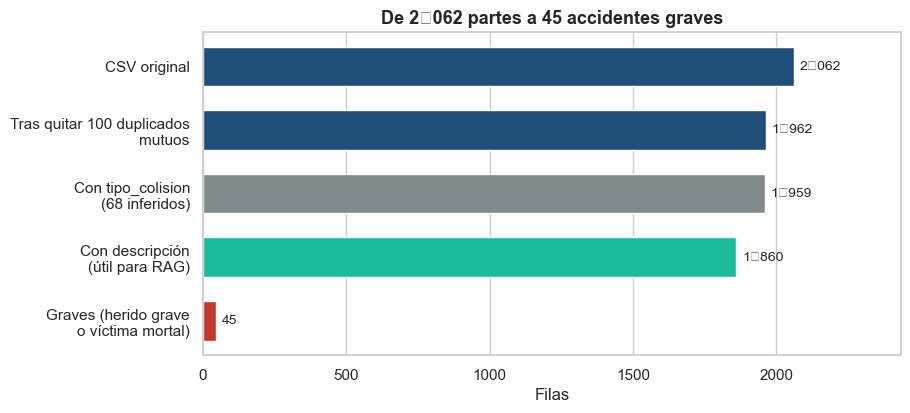

100 números de incidencia aparecen dos veces → se eliminan 100 filas.
tipo_colision vacío: 80 en el bruto, 68 rellenados con la descripción, 3 siguen vacíos (sin texto).
grave = 1 en 45 de 1962 (2.3%).


In [2]:
n_raw = len(raw)
n_dup_ids = raw.loc[raw["numero_incidencia"].duplicated(keep=False), "numero_incidencia"].nunique()
n_removed = n_raw - len(clean)
n_clean = len(clean)
n_grave = int(clean["grave"].sum())
n_infer = int(clean["tipo_colision_inferido"].sum())
n_col_na_raw = int(raw["tipo_colision"].isna().sum())
n_col_na_clean = int(clean["tipo_colision"].isna().sum())
n_desc_na = int(clean["descripcion"].isna().sum())

fig, ax = plt.subplots(figsize=(9, 4.2))
stages = [
    ("CSV original", n_raw),
    (f"Tras quitar {n_dup_ids} duplicados\nmutuos", n_clean),
    ("Con tipo_colision\n(68 inferidos)", n_clean - n_col_na_clean),
    ("Con descripción\n(útil para RAG)", n_clean - n_desc_na),
    ("Graves (herido grave\no víctima mortal)", n_grave),
]
labels, values = zip(*stages)
colors = [PALETTE[0], PALETTE[0], PALETTE[4], PALETTE[3], PALETTE[1]]
bars = ax.barh(labels[::-1], values[::-1], color=colors[::-1], height=0.62)
ax.set_xlabel("Filas")
ax.set_title("De 2 062 partes a 45 accidentes graves")
for bar, value in zip(bars, values[::-1]):
    ax.text(value + 20, bar.get_y() + bar.get_height() / 2, f"{value:,}".replace(",", " "),
            va="center", fontsize=10)
ax.set_xlim(0, n_raw * 1.18)
ax.grid(axis="y", visible=False)
savefig("01_pipeline_filas.png")
plt.show()

print(
    f"{n_dup_ids} números de incidencia aparecen dos veces → se eliminan {n_removed} filas.\n"
    f"tipo_colision vacío: {n_col_na_raw} en el bruto, {n_infer} rellenados con la descripción, {n_col_na_clean} siguen vacíos (sin texto).\n"
    f"grave = 1 en {n_grave} de {n_clean} ({100 * n_grave / n_clean:.1f}%)."
)

data_viz/02_huecos_antes_despues.png


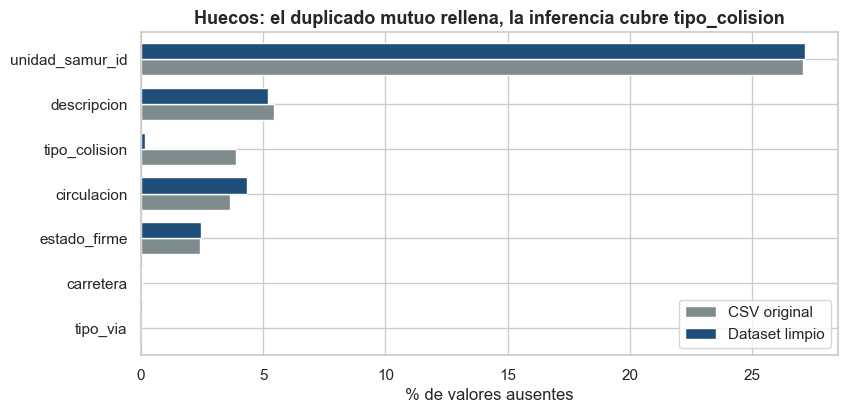

estado_firme bruto (grafías distintas):
estado_firme
Seco y limpio    1618
Mojado            196
(vacío)            50
Seco               40
SECO               37
seco               32
Otros              32
SECO Y LIMPIO      30
Húmedo              9
MOJADO              8
mojado              6
(En blanco)         2

estado_firme limpio:
estado_firme
Seco y limpio    1670
Mojado            203
(vacío)            48
Otros              32
Húmedo              9


In [3]:
compare_cols = [
    "tipo_colision", "descripcion", "circulacion", "estado_firme",
    "unidad_samur_id", "tipo_via", "carretera",
]
missing = pd.DataFrame({
    "bruto": raw[compare_cols].isna().mean() * 100,
    "limpio": clean[compare_cols].isna().mean() * 100,
}).sort_values("bruto")

fig, ax = plt.subplots(figsize=(9, 4.2))
missing.plot(kind="barh", ax=ax, color=[PALETTE[4], PALETTE[0]], width=0.72)
ax.set_xlabel("% de valores ausentes")
ax.set_title("Huecos: el duplicado mutuo rellena, la inferencia cubre tipo_colision")
ax.legend(["CSV original", "Dataset limpio"], loc="lower right")
savefig("02_huecos_antes_despues.png")
plt.show()

firme_raw = raw["estado_firme"].fillna("(vacío)").value_counts()
firme_clean = clean["estado_firme"].fillna("(vacío)").value_counts()
print("estado_firme bruto (grafías distintas):")
print(firme_raw.head(12).to_string())
print("\nestado_firme limpio:")
print(firme_clean.to_string())

data_viz/03_tipo_colision_inferido.png


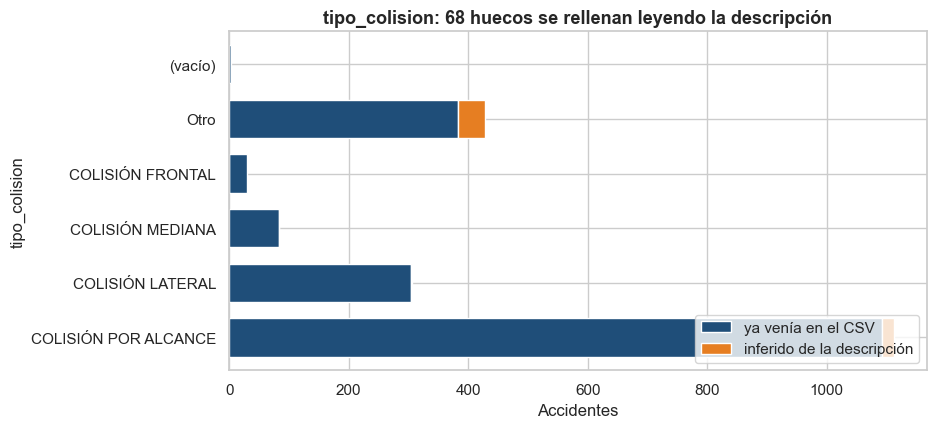

                      ya venía en el CSV  inferido de la descripción
tipo_colision                                                       
COLISIÓN POR ALCANCE                1092                          20
COLISIÓN LATERAL                     304                           2
COLISIÓN MEDIANA                      83                           1
COLISIÓN FRONTAL                      29                           0
Otro                                 383                          45
(vacío)                                3                           0


In [4]:
order = ["COLISIÓN POR ALCANCE", "COLISIÓN LATERAL", "COLISIÓN MEDIANA", "COLISIÓN FRONTAL", "Otro"]
src = clean.copy()
src["tipo_colision"] = src["tipo_colision"].fillna("(vacío)")
known = src.loc[~src["tipo_colision_inferido"], "tipo_colision"].value_counts()
inferred = src.loc[src["tipo_colision_inferido"], "tipo_colision"].value_counts()
mix = pd.DataFrame({"ya venía en el CSV": known, "inferido de la descripción": inferred}).fillna(0)
mix = mix.reindex([*order, "(vacío)"]).fillna(0)

fig, ax = plt.subplots(figsize=(9, 4.4))
mix.plot(kind="barh", stacked=True, ax=ax, color=[PALETTE[0], PALETTE[2]], width=0.7)
ax.set_xlabel("Accidentes")
ax.set_title("tipo_colision: 68 huecos se rellenan leyendo la descripción")
ax.legend(loc="lower right")
savefig("03_tipo_colision_inferido.png")
plt.show()
print(mix.astype(int).to_string())

## 2. Cuándo ocurren

El dataset cubre **2024 entero**. El volumen sigue el tráfico laboral: pocos fines de semana, agosto a la mitad, y dos picos diarios (14–16 h y 18–19 h). La **gravedad no sigue el volumen**: de madrugada hay pocos partes, pero una fracción mayor acaba en herido grave o víctima mortal.

data_viz/04_hora_volumen_gravedad.png


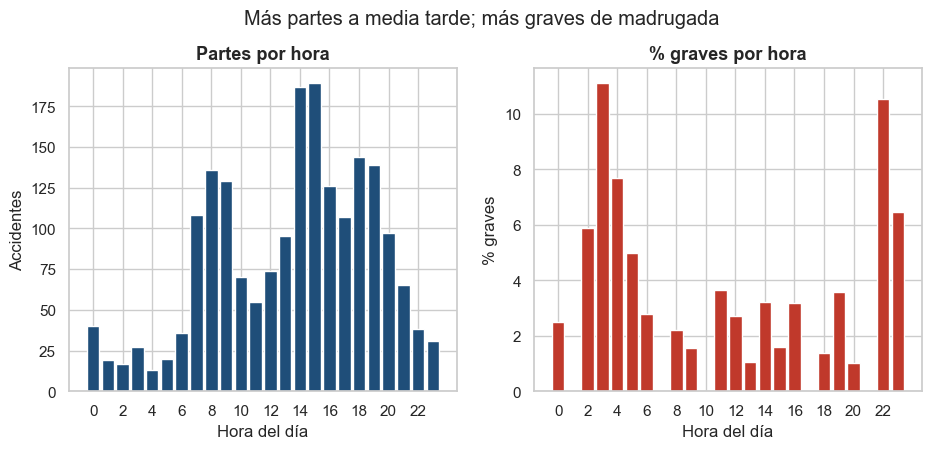

data_viz/05_calendario.png


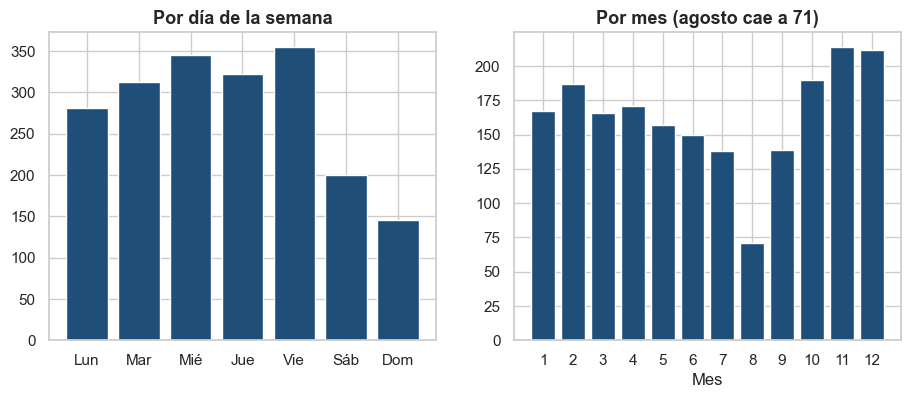

            n  graves   tasa
hora_int                    
0          40       1  0.025
1          19       0  0.000
2          17       1  0.059
3          27       3  0.111
4          13       1  0.077
5          20       1  0.050
6          36       1  0.028
7         108       0  0.000
8         136       3  0.022
9         129       2  0.016
10         70       0  0.000
11         55       2  0.036
12         74       2  0.027
13         95       1  0.011
14        187       6  0.032
15        189       3  0.016
16        126       4  0.032
17        107       0  0.000
18        144       2  0.014
19        139       5  0.036
20         97       1  0.010
21         65       0  0.000
22         38       4  0.105
23         31       2  0.065


In [5]:
by_hour = (
    clean.groupby("hora_int")
    .agg(n=("grave", "size"), graves=("grave", "sum"), tasa=("grave", "mean"))
    .reindex(range(24), fill_value=0)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].bar(by_hour.index, by_hour["n"], color=PALETTE[0], width=0.85)
axes[0].set_title("Partes por hora")
axes[0].set_xlabel("Hora del día")
axes[0].set_ylabel("Accidentes")
axes[0].set_xticks(range(0, 24, 2))

axes[1].bar(by_hour.index, 100 * by_hour["tasa"], color=PALETTE[1], width=0.85)
axes[1].set_title("% graves por hora")
axes[1].set_xlabel("Hora del día")
axes[1].set_ylabel("% graves")
axes[1].set_xticks(range(0, 24, 2))
fig.suptitle("Más partes a media tarde; más graves de madrugada", y=1.02)
savefig("04_hora_volumen_gravedad.png")
plt.show()

wd_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd_es = {"Monday": "Lun", "Tuesday": "Mar", "Wednesday": "Mié", "Thursday": "Jue",
         "Friday": "Vie", "Saturday": "Sáb", "Sunday": "Dom"}
by_wd = clean.assign(wd=clean["fecha"].dt.day_name()).groupby("wd").size().reindex(wd_order)
by_month = clean.groupby(clean["fecha"].dt.month).size().reindex(range(1, 13), fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
axes[0].bar([wd_es[d] for d in wd_order], by_wd.values, color=PALETTE[0])
axes[0].set_title("Por día de la semana")
axes[1].bar(by_month.index, by_month.values, color=PALETTE[0])
axes[1].set_title("Por mes (agosto cae a 71)")
axes[1].set_xticks(range(1, 13))
axes[1].set_xlabel("Mes")
savefig("05_calendario.png")
plt.show()
print(by_hour.loc[by_hour["n"] > 0, ["n", "graves", "tasa"]].round(3).to_string())

## 3. Cómo y dónde

Esto no es una muestra de toda Madrid: **1 625 de 1 962 partes son en la M-30** (83 %). El resto se concentra en radiales (A-2, M-607, A-5…). El alcance es el golpe más frecuente y el menos grave; el frontal y el lateral se cobran más.

data_viz/06_tipo_colision.png


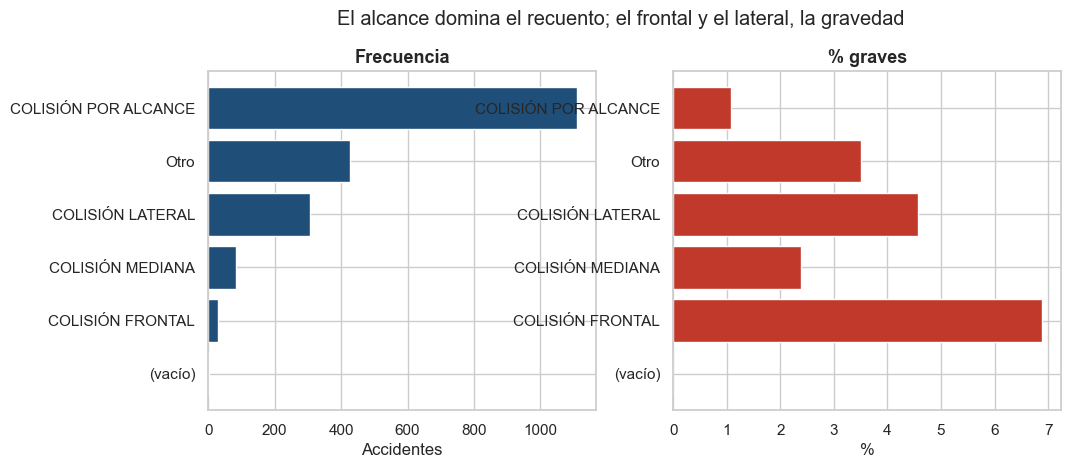

data_viz/07_carreteras.png


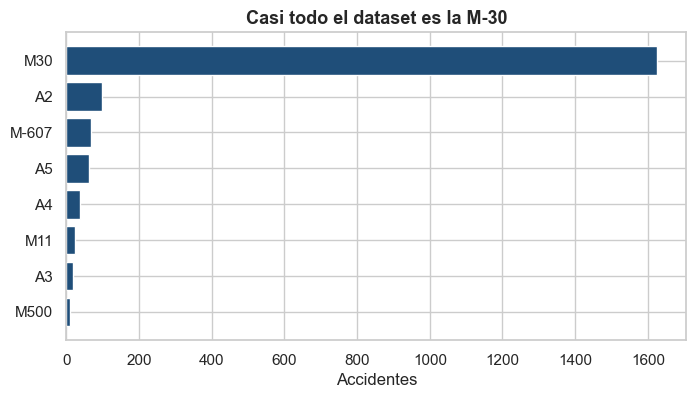

                         n  graves   tasa
tipo                                     
(vacío)                  3       0  0.000
COLISIÓN FRONTAL        29       2  0.069
COLISIÓN MEDIANA        84       2  0.024
COLISIÓN LATERAL       306      14  0.046
Otro                   428      15  0.035
COLISIÓN POR ALCANCE  1112      12  0.011

M-30: 1625 (82.8%)


In [6]:
col = (
    clean.assign(tipo=clean["tipo_colision"].fillna("(vacío)"))
    .groupby("tipo")
    .agg(n=("grave", "size"), graves=("grave", "sum"), tasa=("grave", "mean"))
    .sort_values("n", ascending=True)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].barh(col.index, col["n"], color=PALETTE[0])
axes[0].set_title("Frecuencia")
axes[0].set_xlabel("Accidentes")
axes[1].barh(col.index, 100 * col["tasa"], color=PALETTE[1])
axes[1].set_title("% graves")
axes[1].set_xlabel("%")
fig.suptitle("El alcance domina el recuento; el frontal y el lateral, la gravedad", y=1.02)
savefig("06_tipo_colision.png")
plt.show()

roads = clean["carretera"].fillna("(vacío)").value_counts().head(8).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.0))
ax.barh(roads.index.astype(str), roads.values, color=PALETTE[0])
ax.set_title("Casi todo el dataset es la M-30")
ax.set_xlabel("Accidentes")
savefig("07_carreteras.png")
plt.show()
print(col.round(3).to_string())
print("\nM-30:", int((clean["carretera"] == "M30").sum()), f"({100 * (clean['carretera'] == 'M30').mean():.1f}%)")

data_viz/08_distritos.png


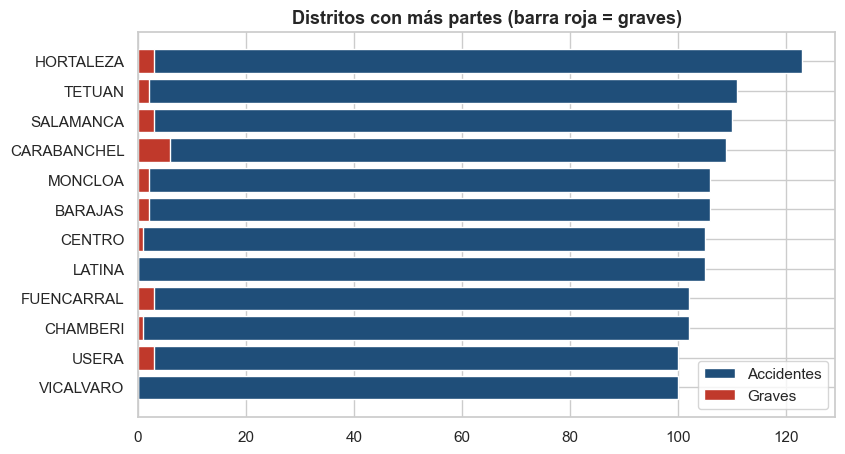

               n  graves   tasa
distrito                       
HORTALEZA    123       3  0.024
TETUAN       111       2  0.018
SALAMANCA    110       3  0.027
CARABANCHEL  109       6  0.055
BARAJAS      106       2  0.019
MONCLOA      106       2  0.019
LATINA       105       0  0.000
CENTRO       105       1  0.010
CHAMBERI     102       1  0.010
FUENCARRAL   102       3  0.029
VICALVARO    100       0  0.000
USERA        100       3  0.030

Carabanchel: más graves entre los distritos con volumen alto.


In [7]:
dist = (
    clean.groupby("distrito")
    .agg(n=("grave", "size"), graves=("grave", "sum"), tasa=("grave", "mean"))
    .sort_values("n", ascending=False)
    .head(12)
    .sort_values("n")
)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(dist.index, dist["n"], color=PALETTE[0], label="Accidentes")
ax.barh(dist.index, dist["graves"], color=PALETTE[1], label="Graves")
ax.set_title("Distritos con más partes (barra roja = graves)")
ax.legend(loc="lower right")
savefig("08_distritos.png")
plt.show()
print(dist.sort_values("n", ascending=False).round(3).to_string())
print("\nCarabanchel: más graves entre los distritos con volumen alto.")

## 4. Dónde se concentra la gravedad

`grave` vale 1 si hay heridos graves o víctimas mortales: **45 casos (2,3 %)**. 40 con herido grave, 7 con víctima mortal (2 coinciden). La señal más clara no es el distrito ni la hora, es **si va una moto**.

data_viz/09_factores_gravedad.png


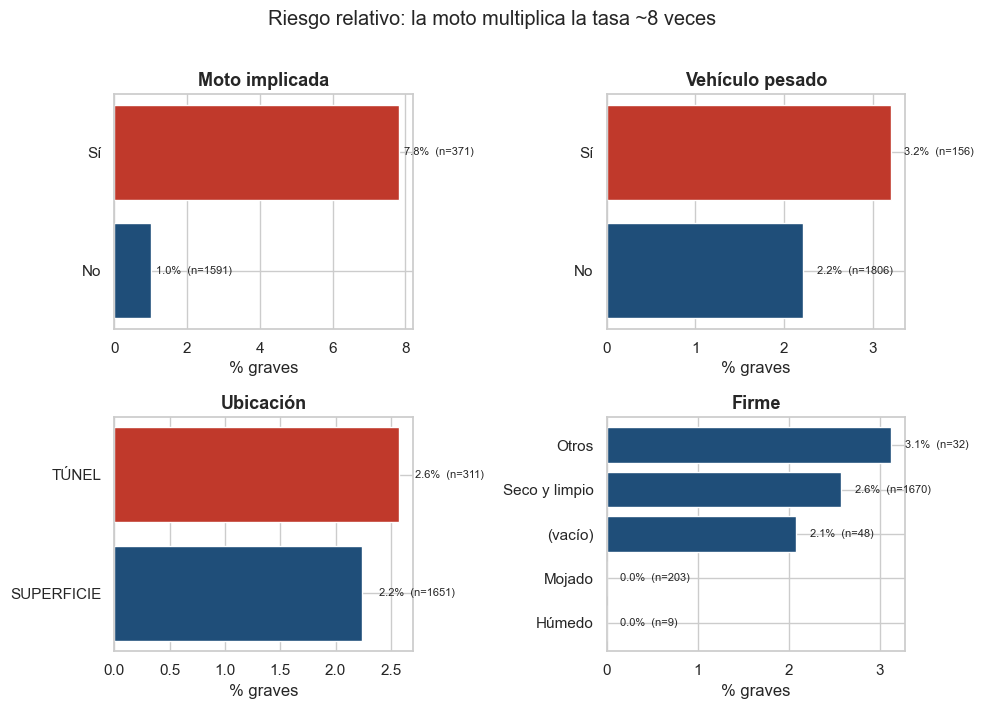


Moto implicada
       n  graves   tasa  tasa_pct
g                                
No  1591      16  0.010     1.006
Sí   371      29  0.078     7.817

Vehículo pesado
       n  graves   tasa  tasa_pct
g                                
No  1806      40  0.022     2.215
Sí   156       5  0.032     3.205

Ubicación
               n  graves   tasa  tasa_pct
ubicacion                                
SUPERFICIE  1651      37  0.022     2.241
TÚNEL        311       8  0.026     2.572

Firme
                  n  graves   tasa  tasa_pct
estado_firme                                
(vacío)          48       1  0.021     2.083
Húmedo            9       0  0.000     0.000
Mojado          203       0  0.000     0.000
Otros            32       1  0.031     3.125
Seco y limpio  1670      43  0.026     2.575

Heridos graves > 0: 40 | víctimas mortales > 0: 7 | ambas: 2


In [8]:
def rate_table(frame, col):
    return (
        frame.groupby(col)["grave"]
        .agg(n="size", graves="sum", tasa="mean")
        .assign(tasa_pct=lambda d: 100 * d["tasa"])
    )

risk_blocks = {
    "Moto implicada": rate_table(clean.assign(g=np.where(clean["con_moto"], "Sí", "No")), "g"),
    "Vehículo pesado": rate_table(clean.assign(g=np.where(clean["con_pesado"], "Sí", "No")), "g"),
    "Ubicación": rate_table(clean, "ubicacion"),
    "Firme": rate_table(clean.fillna({"estado_firme": "(vacío)"}), "estado_firme"),
}

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (title, table) in zip(axes.ravel(), risk_blocks.items()):
    table = table.sort_values("tasa_pct")
    colors = [PALETTE[1] if idx in {"Sí", "TÚNEL"} else PALETTE[0] for idx in table.index]
    ax.barh(table.index.astype(str), table["tasa_pct"], color=colors)
    for y, (n, pct) in enumerate(zip(table["n"], table["tasa_pct"])):
        ax.text(pct + 0.15, y, f"{pct:.1f}%  (n={int(n)})", va="center", fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("% graves")
fig.suptitle("Riesgo relativo: la moto multiplica la tasa ~8 veces", y=1.01)
fig.tight_layout()
savefig("09_factores_gravedad.png")
plt.show()

for title, table in risk_blocks.items():
    print(f"\n{title}")
    print(table.round(3).to_string())

print(
    "\nHeridos graves > 0:", int((clean["heridos_graves"] > 0).sum()),
    "| víctimas mortales > 0:", int((clean["victimas_mortales"] > 0).sum()),
    "| ambas:", int(((clean["heridos_graves"] > 0) & (clean["victimas_mortales"] > 0)).sum()),
)

## 5. Qué implica esto para el RAG

El agente busca **descripciones**, no recuentos. 102 partes no tienen texto: esos accidentes no entran en Pinecone. El resto cabe en un vector por informe. Los 68 `tipo_colision` inferidos sí quedan en la tabla limpia y se pueden usar como filtro, pero la búsqueda semántica solo ve lo escrito en `descripcion`.

data_viz/10_cobertura_descripcion.png


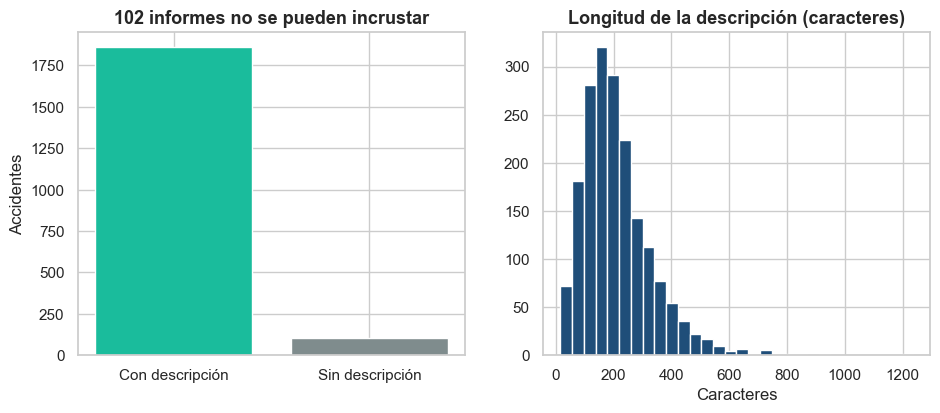

count    1860.0
mean      212.0
std       119.0
min        16.0
25%       128.0
50%       189.0
75%       265.0
max      1235.0

Sin descripción y graves: 1


In [9]:
clean["chars"] = clean["descripcion"].fillna("").str.len()
with_text = clean["descripcion"].notna()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].bar(
    ["Con descripción", "Sin descripción"],
    [int(with_text.sum()), int((~with_text).sum())],
    color=[PALETTE[3], PALETTE[4]],
)
axes[0].set_title(f"{int((~with_text).sum())} informes no se pueden incrustar")
axes[0].set_ylabel("Accidentes")

axes[1].hist(clean.loc[with_text, "chars"], bins=30, color=PALETTE[0], edgecolor="white")
axes[1].set_title("Longitud de la descripción (caracteres)")
axes[1].set_xlabel("Caracteres")
savefig("10_cobertura_descripcion.png")
plt.show()

print(clean.loc[with_text, "chars"].describe().round(0).to_string())
print("\nSin descripción y graves:", int((~with_text & clean["grave"].eq(1)).sum()))

## Lectura corta

1. **Limpieza.** 100 duplicados mutuos, categorías unificadas (`seco` / `SECO` / `Seco y limpio` → una sola grafía) y 68 tipos de colisión leídos de la descripción. Quedan 3 `tipo_colision` vacíos, todos sin texto.
2. **Volumen.** Laborable, M-30, picos de tarde. Agosto se hunde. No es un censo de accidentes de Madrid: es el recorte SAMUR de estas vías.
3. **Gravedad.** Clase rara (2,3 %). El alcance es el más común y el más leve. **Moto: 7,8 % graves frente a 1,0 % sin moto.** De madrugada hay pocos partes y más proporción grave.
4. **RAG.** 1 860 descripciones indexables; 102 mudas. El chat no puede “contar” estos gráficos: para eso está este cuaderno.

Figuras escritas en `data_viz/graficos_accidentes/` (`01_…` a `10_…`).